In [11]:
# Konfiguracja wyglądu punktów i linii dopasowania
POINT_STYLES = {
    "rainy": {
        "stations": {"color": "#80C4E9", "size": 30, "alpha": 0.40, "linewidth": 0},
        "binned": {"color": "#102A43", "size": 70, "alpha": 0.7, "marker": "D"},
        "excluded": {"facecolor": "white", "edgecolor": "#102A43", "size": 70, "alpha": 0.7, "marker": "D", "linewidth": 2},
        "fit": "#8054A3",
        "marker": "o",
    },
    "non_rainy": {
        "stations": {"color": "#8FD6AC", "size": 30, "alpha": 0.40, "linewidth": 0},
        "binned": {"color": "#216B50", "size": 70, "alpha": 0.7, "marker": "D"},
        "excluded": {"facecolor": "white", "edgecolor": "#216B50", "size": 70, "alpha": 0.7, "marker": "D", "linewidth": 2},
        "fit": "#D18A36",
        "marker": "s",
    },
}

from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.legend_handler import HandlerBase
from PIL import Image, ImageDraw
from xml.etree import ElementTree as ET
import numpy as np
import openmeteo_requests
import requests_cache
from retry_requests import retry
from matplotlib.lines import Line2D

def _apply_project_plot_style():
    current = Path.cwd()
    for path in [current, *current.parents]:
        if (path / "plot_style.py").is_file():
            if str(path) not in sys.path:
                sys.path.insert(0, str(path))

            import plot_style

            plot_style.apply_montserrat_style()
            return

_apply_project_plot_style()

In [12]:
def find_project_root(start=None):
    current = Path.cwd() if start is None else Path(start)
    for path in [current, *current.parents]:
        if (path / "Data").exists():
            return path
    raise FileNotFoundError("Could not find project root containing Data/")


PROJECT_ROOT = find_project_root()
BASE_DIR = PROJECT_ROOT
DATA_DIR = PROJECT_ROOT / "Data"
DATA_FILE = DATA_DIR / "rides_data_without_discontinuities.parquet"

rides_data = pd.read_parquet(DATA_FILE, columns=[
    "start_station_id", "start_station_name", "start_date", "start_day_of_week"
])


def load_svg_icon(path, size=64):
    root = ET.parse(path).getroot()
    min_x, min_y, view_width, view_height = map(float, root.attrib["viewBox"].split())
    scale_x = size / view_width
    scale_y = size / view_height
    image = Image.new("RGBA", (size, size), (0, 0, 0, 0))
    draw = ImageDraw.Draw(image)

    def point(x, y):
        return ((float(x) - min_x) * scale_x, (float(y) - min_y) * scale_y)

    for element in root:
        tag = element.tag.rsplit("}", 1)[-1]
        fill = element.get("fill")
        stroke = element.get("stroke")
        width = max(1, round(float(element.get("stroke-width", 1)) * (scale_x + scale_y) / 2))
        if tag == "circle":
            cx, cy, radius = (float(element.get(key)) for key in ("cx", "cy", "r"))
            upper_left = point(cx - radius, cy - radius)
            lower_right = point(cx + radius, cy + radius)
            draw.ellipse((upper_left, lower_right), fill=None if fill == "none" else fill,
                         outline=stroke, width=width)
        elif tag == "line":
            draw.line((point(element.get("x1"), element.get("y1")),
                       point(element.get("x2"), element.get("y2"))), fill=stroke, width=width)
        elif tag == "polygon":
            coords = [float(value) for value in element.get("points", "").replace(",", " ").split()]
            points = [point(coords[i], coords[i + 1]) for i in range(0, len(coords), 2)]
            draw.polygon(points, fill=None if fill == "none" else fill, outline=stroke, width=width)
    return image


class SVGIcon:
    def __init__(self, image):
        self.image = image


class HandlerSVGIcon(HandlerBase):
    def create_artists(self, legend, orig_handle, xdescent, ydescent, width, height, fontsize, trans):
        image = OffsetImage(orig_handle.image, zoom=0.18)
        icon = AnnotationBbox(
            image,
            (xdescent + width / 2, ydescent + height / 2),
            xycoords=trans,
            box_alignment=(0.5, 0.5),
            frameon=False,
            pad=0,
        )
        return [icon]


RAIN_ICON = SVGIcon(load_svg_icon(PROJECT_ROOT / "notebooks_made_by_me" / "weather_rain.svg"))
SUN_ICON = SVGIcon(load_svg_icon(PROJECT_ROOT / "notebooks_made_by_me" / "weather_sun.svg"))


In [13]:
from log_binning import log_binning_aw

In [14]:
# Setup the Open-Meteo API client with cache and retry on error
cache_session = requests_cache.CachedSession('.cache', expire_after = -1)
retry_session = retry(cache_session, retries = 5, backoff_factor = 0.2)
openmeteo = openmeteo_requests.Client(session = retry_session)

# Make sure all required weather variables are listed here
# The order of variables in hourly or daily is important to assign them correctly below
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
	"latitude": 51.5085,
	"longitude": -0.1257,
	"start_date": "2025-05-01",
	"end_date": "2025-05-31",
	"daily": "rain_sum",
}
responses = openmeteo.weather_api(url, params = params)

# Process first location. Add a for-loop for multiple locations or weather models
response = responses[0]
print(f"Coordinates: {response.Latitude()}°N {response.Longitude()}°E")
print(f"Elevation: {response.Elevation()} m asl")
print(f"Timezone difference to GMT+0: {response.UtcOffsetSeconds()}s")

# Process daily data. The order of variables needs to be the same as requested.
daily = response.Daily()
daily_rain_sum = daily.Variables(0).ValuesAsNumpy()

daily_data = {
	"date": pd.date_range(
		start = pd.to_datetime(daily.Time(), unit = "s", utc = True),
		end =  pd.to_datetime(daily.TimeEnd(), unit = "s", utc = True),
		freq = pd.Timedelta(seconds = daily.Interval()),
		inclusive = "left"
	)
}

daily_data["rain_sum"] = daily_rain_sum

daily_dataframe = pd.DataFrame(data = daily_data)
daily_dataframe.head(5)

Coordinates: 51.49384689331055°N -0.16302490234375°E
Elevation: 23.0 m asl
Timezone difference to GMT+0: 0s


,date,rain_sum
0,2025-05-01 00:00:00+00:00,0.0
1,2025-05-02 00:00:00+00:00,1.5
2,2025-05-03 00:00:00+00:00,0.0
3,2025-05-04 00:00:00+00:00,0.0
4,2025-05-05 00:00:00+00:00,0.9


In [15]:
# Dostosowanie danych pogodowych do danych o wypożyczeniach rowerów
daily_dataframe["date"] = daily_dataframe["date"].dt.date

daily_dataframe.head(5)

,date,rain_sum
0,2025-05-01,0.0
1,2025-05-02,1.5
2,2025-05-03,0.0
3,2025-05-04,0.0
4,2025-05-05,0.9


In [16]:
may_2025 = rides_data[
    (rides_data["start_date"].dt.year == 2025) &
    (rides_data["start_date"].dt.month == 5)
]

# Zamiana kolumny "start_date" na typ daty bez czasu
may_2025["start_date"] = may_2025["start_date"].dt.date

may_2025.head(-5)

,start_station_id,start_station_name,start_date,start_day_of_week
618,300205,"Cromer Street, Bloomsbury",2025-05-01,Thursday
619,1009,"Taviton Street, Bloomsbury",2025-05-01,Thursday
620,1022,"Brunswick Square, Bloomsbury",2025-05-01,Thursday
621,1022,"Brunswick Square, Bloomsbury",2025-05-01,Thursday
622,1022,"Brunswick Square, Bloomsbury",2025-05-02,Friday
...,...,...,...,...
16293412,200146,"Newby Place, Poplar",2025-05-30,Friday
16293413,984,"Finsbury Circus, Liverpool Street",2025-05-30,Friday
16293414,960,"Hop Exchange, The Borough",2025-05-30,Friday
16293415,1064,"Old Street Station, St. Luke's",2025-05-31,Saturday


In [17]:
# Czy stacja była aktywna przez cały miesiąc?

station_activity = (
    may_2025
    .groupby("start_station_id")["start_date"]
    .agg(days_with_rides="nunique")
)

station_activity.head(-5)

,days_with_rides
start_station_id,
959,31
960,31
961,31
962,31
963,31
...,...
300242,31
300243,31
300244,31


In [18]:
# Wybieramy tylko stacje, które były aktywne przez cały miesiąc

valid_stations = station_activity[station_activity["days_with_rides"] == 31].index
may_2025_filtered = may_2025[may_2025["start_station_id"].isin(valid_stations)]
may_2025_filtered.head(-5)

,start_station_id,start_station_name,start_date,start_day_of_week
618,300205,"Cromer Street, Bloomsbury",2025-05-01,Thursday
619,1009,"Taviton Street, Bloomsbury",2025-05-01,Thursday
620,1022,"Brunswick Square, Bloomsbury",2025-05-01,Thursday
621,1022,"Brunswick Square, Bloomsbury",2025-05-01,Thursday
622,1022,"Brunswick Square, Bloomsbury",2025-05-02,Friday
...,...,...,...,...
16293412,200146,"Newby Place, Poplar",2025-05-30,Friday
16293413,984,"Finsbury Circus, Liverpool Street",2025-05-30,Friday
16293414,960,"Hop Exchange, The Borough",2025-05-30,Friday
16293415,1064,"Old Street Station, St. Luke's",2025-05-31,Saturday


In [19]:
# Dodanie danych pogodowych do danych o wypożyczeniach rowerów
may_2025_filtered = may_2025_filtered.merge(
    daily_dataframe,
    how = "left",
    left_on = "start_date",
    right_on = "date"
)

may_2025_filtered.head(5)

,start_station_id,start_station_name,start_date,start_day_of_week,date,rain_sum
0,300205,"Cromer Street, Bloomsbury",2025-05-01,Thursday,2025-05-01,0.0
1,1009,"Taviton Street, Bloomsbury",2025-05-01,Thursday,2025-05-01,0.0
2,1022,"Brunswick Square, Bloomsbury",2025-05-01,Thursday,2025-05-01,0.0
3,1022,"Brunswick Square, Bloomsbury",2025-05-01,Thursday,2025-05-01,0.0
4,1022,"Brunswick Square, Bloomsbury",2025-05-02,Friday,2025-05-02,1.5


In [20]:
# Podział na dni deszczowe i bezdeszczowe
may_2025_rainy = may_2025_filtered[may_2025_filtered["rain_sum"] > 0]
may_2025_non_rainy = may_2025_filtered[may_2025_filtered["rain_sum"] == 0]

rainy_days_count = int((daily_dataframe["rain_sum"] > 0).sum())
non_rainy_days_count = int((daily_dataframe["rain_sum"] == 0).sum())

print(f"Liczba dni deszczowych: {rainy_days_count}")
print(f"Liczba dni bezdeszczowych: {non_rainy_days_count}")


Liczba dni deszczowych: 14
Liczba dni bezdeszczowych: 17


In [21]:
# Policzenie ile było przejazdów dla każdej stacji dzień po dniu, osobno dla dni deszczowych i osobno dla dni bezdeszczowych
daily_rides_per_station_rainy = (
    may_2025_rainy
    .groupby(["start_station_id", "start_date"])
    .size()
    .unstack()
)

daily_rides_per_station_non_rainy = (
    may_2025_non_rainy
    .groupby(["start_station_id", "start_date"])
    .size()
    .unstack()
)

In [22]:
# Średnia i wariancja dla każdej stacji, osobno dla dni deszczowych i osobno dla dni bezdeszczowych

mean_and_variance_counts_rainy = pd.DataFrame({
    "mean_count": daily_rides_per_station_rainy.mean(axis=1),
    "variance": daily_rides_per_station_rainy.var(axis=1, ddof=0)
}).reset_index()

mean_and_variance_counts_non_rainy = pd.DataFrame({
    "mean_count": daily_rides_per_station_non_rainy.mean(axis=1),
    "variance": daily_rides_per_station_non_rainy.var(axis=1, ddof=0)
}).reset_index()

alpha = 1.625
A = 0.345


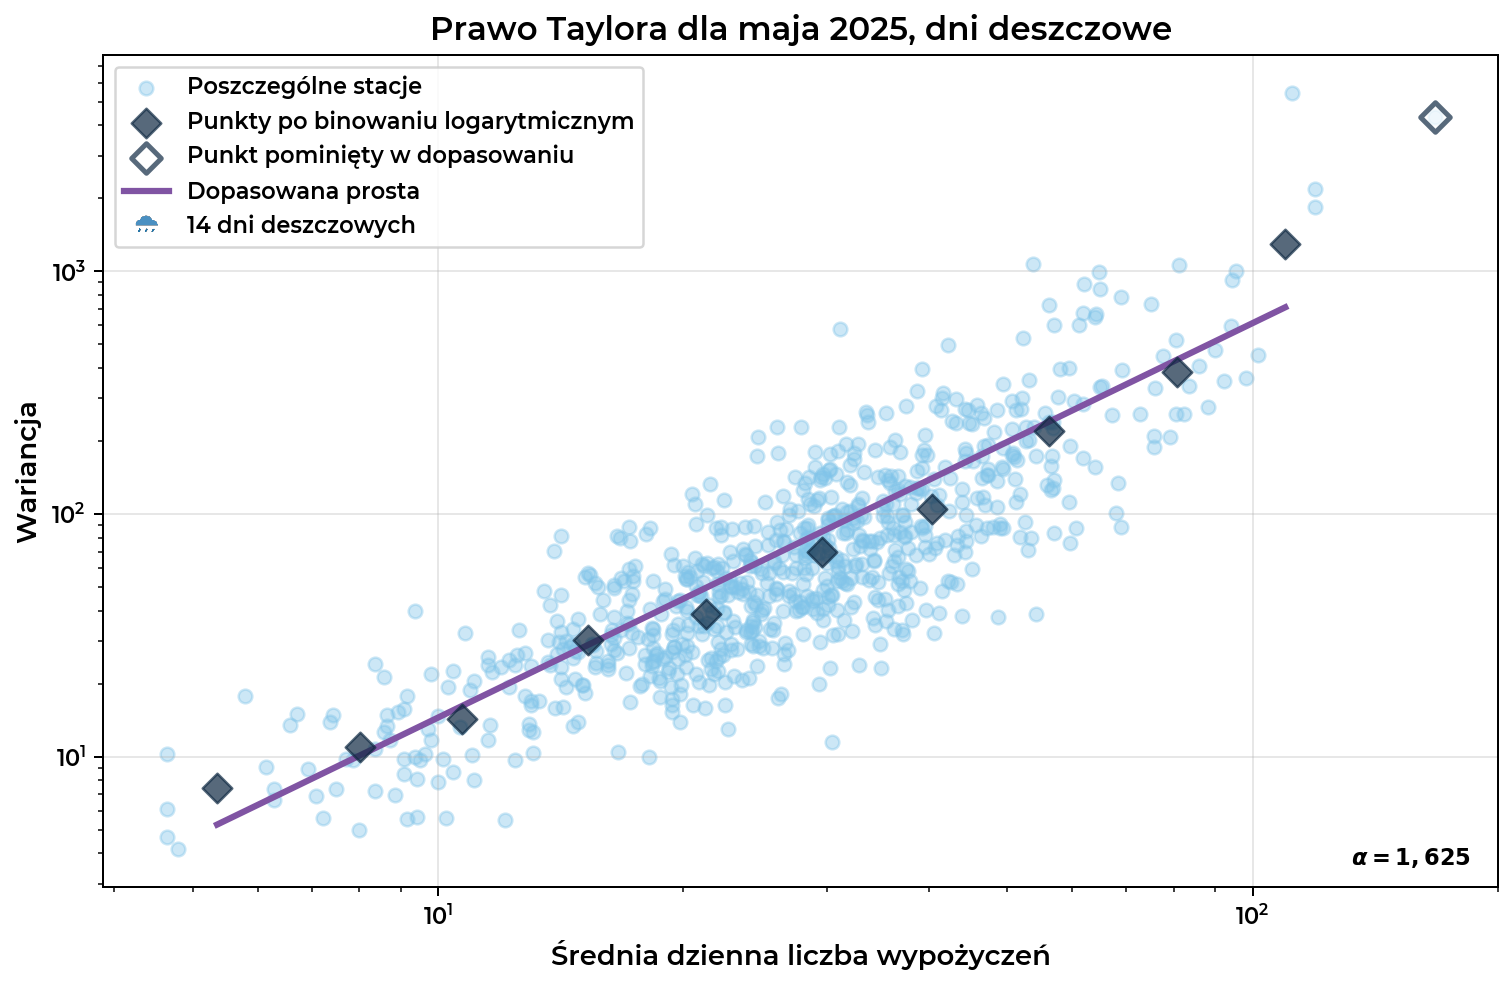

In [23]:
# Dni deszczowe
styles = POINT_STYLES["rainy"]

# Binowanie logarytmiczne
mean_log, variance_log = log_binning_aw(
    mean_and_variance_counts_rainy["mean_count"],
    mean_and_variance_counts_rainy["variance"],
    a=1.4
)

# Dopasowanie prawa Taylora z pominięciem ostatniego punktu
x = np.log(mean_log[:-1])
y = np.log(variance_log[:-1])

alpha, log_A = np.polyfit(x, y, 1)
A = np.exp(log_A)

print(f"alpha = {alpha:.3f}")
print(f"A = {A:.3f}")

# Generowanie punktów dopasowanej funkcji
x_fit = np.geomspace(min(mean_log[:-1]), max(mean_log[:-1]), 100)
y_fit = A * x_fit**alpha

# Wykres
plt.figure(figsize=(10, 6))

# Chmura punktów – poszczególne stacje
plt.scatter(
    mean_and_variance_counts_rainy["mean_count"],
    mean_and_variance_counts_rainy["variance"],
    color=styles["stations"]["color"],
    marker=styles["marker"],
    alpha=styles["stations"]["alpha"],
    s=styles["stations"]["size"],
    zorder=1,
    label="Poszczególne stacje"
)

# Punkty po binowaniu uwzględnione w dopasowaniu
plt.scatter(
    mean_log[:-1],
    variance_log[:-1],
    color=styles["binned"]["color"],
    alpha=styles["binned"]["alpha"],
    marker=styles["binned"]["marker"],
    s=styles["binned"]["size"],
    zorder=3,
    label="Punkty po binowaniu logarytmicznym"
)

# Ostatni punkt pominięty w dopasowaniu
plt.scatter(
    mean_log[-1],
    variance_log[-1],
    marker=styles["excluded"]["marker"],
    facecolors=styles["excluded"]["facecolor"],
    edgecolors=styles["excluded"]["edgecolor"],
    alpha=styles["excluded"]["alpha"],
    linewidths=styles["excluded"]["linewidth"],
    s=styles["excluded"]["size"],
    zorder=3,
    label="Punkt pominięty w dopasowaniu",
)

alpha_str = f"{alpha:.3f}".replace(".", ",")

# Dopasowana funkcja potęgowa
plt.plot(
    x_fit,
    y_fit,
    color=styles["fit"],
    linewidth=2.5,
    zorder=2,
    label="Dopasowana prosta"
)

# Skala logarytmiczna
plt.xscale("log")
plt.yscale("log")

# Opisy wykresu
plt.xlabel("Średnia dzienna liczba wypożyczeń")
plt.ylabel("Wariancja")
plt.title("Prawo Taylora dla maja 2025, dni deszczowe")

plt.grid(alpha=0.3)
ax = plt.gca()
ax.text(
    0.98, 0.02,
    fr"$\alpha = {alpha_str}$",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
    fontweight="bold",
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=2),
)
legend_handles, legend_labels = ax.get_legend_handles_labels()
legend_handles.append(RAIN_ICON)
legend_labels.append(f"{rainy_days_count} dni deszczowych")
ax.legend(legend_handles, legend_labels, handler_map={SVGIcon: HandlerSVGIcon()})
plt.show()

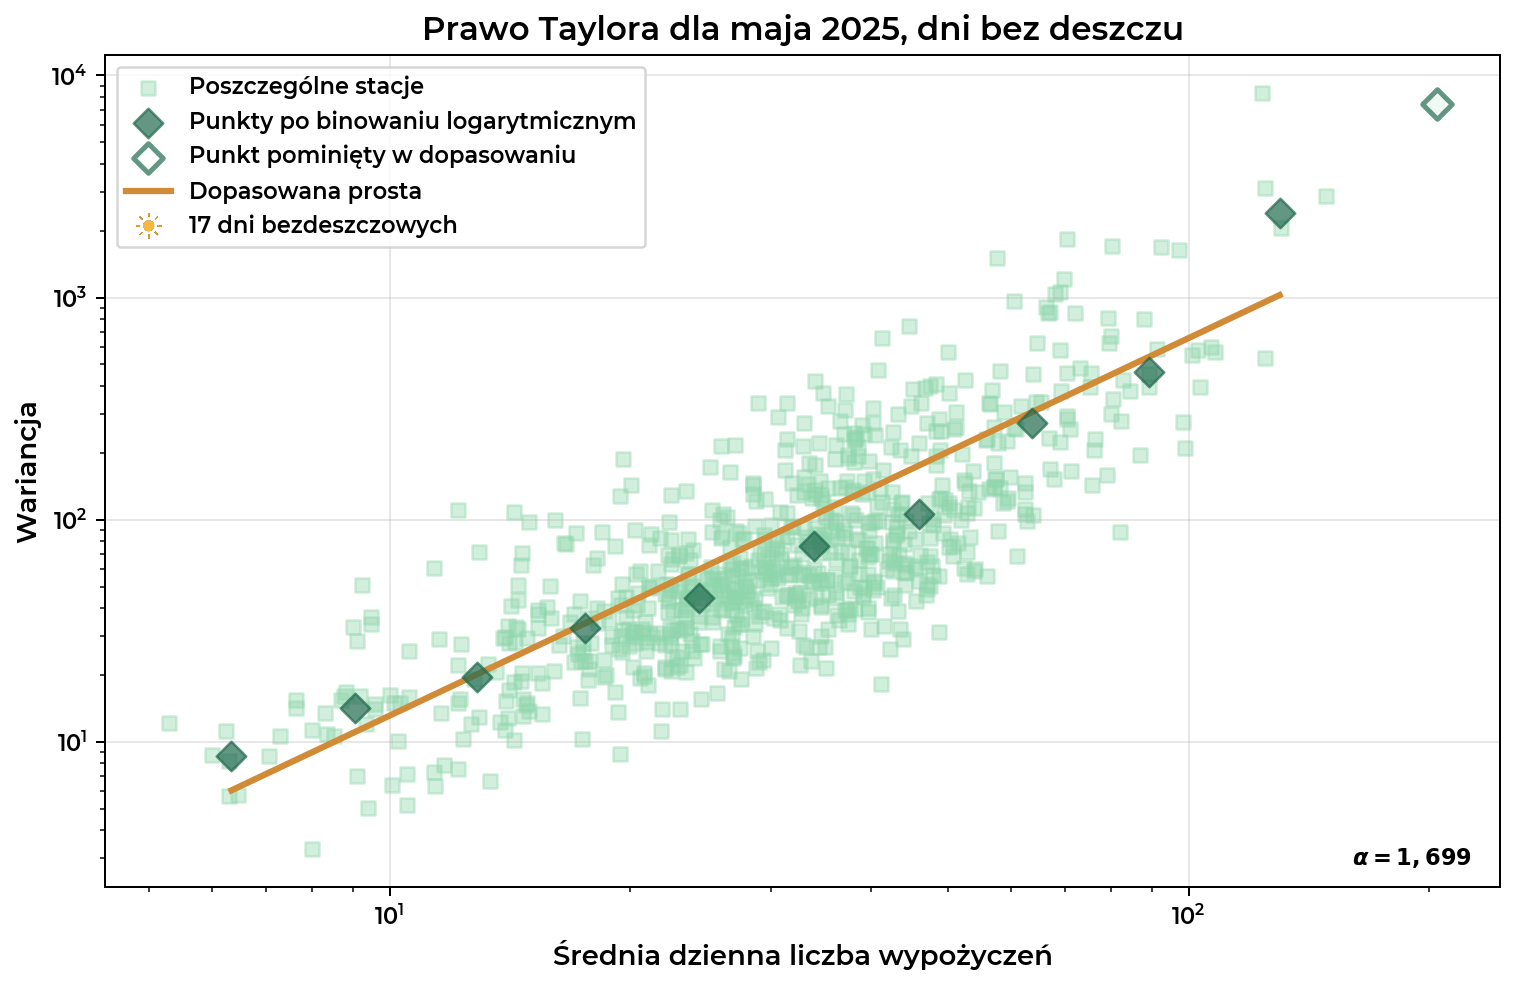

In [24]:
# Dni bez deszczu
styles = POINT_STYLES["non_rainy"]

# Binowanie logarytmiczne
mean_log, variance_log = log_binning_aw(
    mean_and_variance_counts_non_rainy["mean_count"],
    mean_and_variance_counts_non_rainy["variance"],
    a=1.4
)

# Dopasowanie prawa Taylora z pominięciem ostatniego punktu
x = np.log(mean_log[:-1])
y = np.log(variance_log[:-1])

alpha, log_A = np.polyfit(x, y, 1)
A = np.exp(log_A)

# Generowanie punktów dopasowanej funkcji
x_fit = np.geomspace(min(mean_log[:-1]), max(mean_log[:-1]), 100)
y_fit = A * x_fit**alpha

# Wykres
plt.figure(figsize=(10, 6))

# Chmura punktów – poszczególne stacje
plt.scatter(
    mean_and_variance_counts_non_rainy["mean_count"],
    mean_and_variance_counts_non_rainy["variance"],
    color=styles["stations"]["color"],
    marker=styles["marker"],
    alpha=styles["stations"]["alpha"],
    s=styles["stations"]["size"],
    zorder=1,
    label="Poszczególne stacje"
)

# Punkty po binowaniu uwzględnione w dopasowaniu
plt.scatter(
    mean_log[:-1],
    variance_log[:-1],
    color=styles["binned"]["color"],
    alpha=styles["binned"]["alpha"],
    marker=styles["binned"]["marker"],
    s=styles["binned"]["size"],
    zorder=3,
    label="Punkty po binowaniu logarytmicznym"
)

# Ostatni punkt pominięty w dopasowaniu
plt.scatter(
    mean_log[-1],
    variance_log[-1],
    marker=styles["excluded"]["marker"],
    facecolors=styles["excluded"]["facecolor"],
    edgecolors=styles["excluded"]["edgecolor"],
    alpha=styles["excluded"]["alpha"],
    linewidths=styles["excluded"]["linewidth"],
    s=styles["excluded"]["size"],
    zorder=3,
    label="Punkt pominięty w dopasowaniu",
)

alpha_str = f"{alpha:.3f}".replace(".", ",")

# Dopasowana funkcja potęgowa
plt.plot(
    x_fit,
    y_fit,
    color=styles["fit"],
    linewidth=2.5,
    zorder=2,
    label="Dopasowana prosta"
)

# Skala logarytmiczna
plt.xscale("log")
plt.yscale("log")

# Opisy wykresu
plt.xlabel("Średnia dzienna liczba wypożyczeń")
plt.ylabel("Wariancja")
plt.title("Prawo Taylora dla maja 2025, dni bez deszczu")

plt.grid(alpha=0.3)
ax = plt.gca()
ax.text(
    0.98, 0.02,
    fr"$\alpha = {alpha_str}$",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
    fontweight="bold",
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=2),
)
legend_handles, legend_labels = ax.get_legend_handles_labels()
legend_handles.append(SUN_ICON)
legend_labels.append(f"{non_rainy_days_count} dni bezdeszczowych")
ax.legend(legend_handles, legend_labels, handler_map={SVGIcon: HandlerSVGIcon()})
plt.show()

Dni deszczowe: alpha = 1.625, A = 0.345
Dni bezdeszczowe: alpha = 1.699, A = 0.262


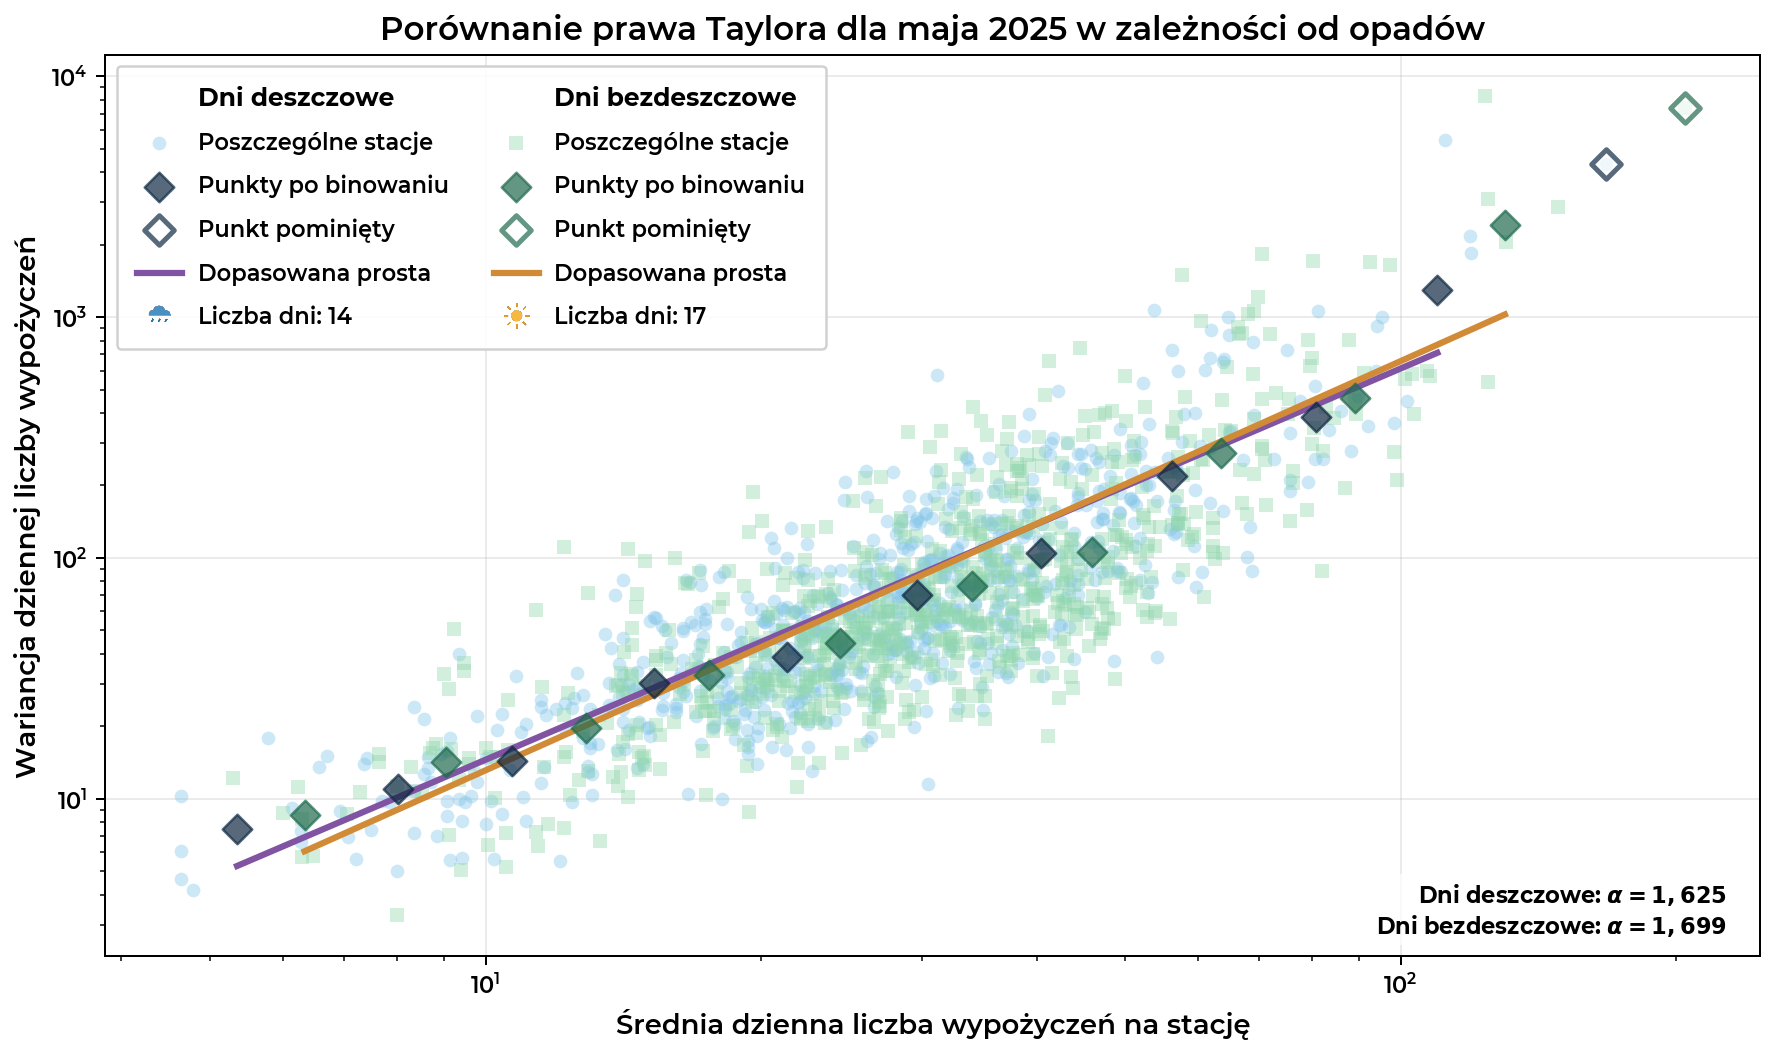

In [25]:
# Porównanie prawa Taylora dla dni deszczowych i bezdeszczowych

from matplotlib.lines import Line2D

# Dane do porównania
datasets = {
    "rainy": {
        "data": mean_and_variance_counts_rainy,
        "label": "Dni deszczowe"
    },
    "non_rainy": {
        "data": mean_and_variance_counts_non_rainy,
        "label": "Dni bezdeszczowe"
    }
}

# Wykres
fig, ax = plt.subplots(figsize=(10, 6))
alpha_values = {}

# Analiza obu grup
for weather, config in datasets.items():

    data = config["data"]
    label = config["label"]
    styles = POINT_STYLES[weather]

    # Binowanie logarytmiczne
    mean_log, variance_log = log_binning_aw(
        data["mean_count"],
        data["variance"],
        a=1.4
    )

    # Dopasowanie prawa Taylora z pominięciem ostatniego punktu
    x = np.log(mean_log[:-1])
    y = np.log(variance_log[:-1])

    alpha, log_A = np.polyfit(x, y, 1)
    alpha_values[weather] = alpha
    A = np.exp(log_A)

    # Generowanie punktów dopasowanej funkcji
    x_fit = np.geomspace(
        min(mean_log[:-1]),
        max(mean_log[:-1]),
        100
    )
    y_fit = A * x_fit**alpha

    # Chmura punktów – poszczególne stacje
    ax.scatter(
        data["mean_count"],
        data["variance"],
        color=styles["stations"]["color"],
        marker=styles["marker"],
        alpha=styles["stations"]["alpha"],
        s=styles["stations"]["size"],
        edgecolors=styles["binned"]["color"],
        linewidths=styles["stations"]["linewidth"],
        zorder=1,
        label=f"Stacje - {label.lower()}"
    )

    # Punkty po binowaniu uwzględnione w dopasowaniu
    ax.scatter(
        mean_log[:-1],
        variance_log[:-1],
        color=styles["binned"]["color"],
        alpha=styles["binned"]["alpha"],
        marker=styles["binned"]["marker"],
        s=styles["binned"]["size"],
        zorder=3,
        label=f"Binowanie - {label.lower()}"
    )

    # Ostatni punkt pominięty w dopasowaniu
    ax.scatter(
        mean_log[-1],
        variance_log[-1],
        marker=styles["excluded"]["marker"],
        facecolors=styles["excluded"]["facecolor"],
        edgecolors=styles["excluded"]["edgecolor"],
        alpha=styles["excluded"]["alpha"],
        linewidths=styles["excluded"]["linewidth"],
        s=styles["excluded"]["size"],
        zorder=4,
        label=f"Punkt pominięty - {label.lower()}"
    )

    # Formatowanie wykładnika alfa
    alpha_str = f"{alpha:.3f}".replace(".", ",")

    # Dopasowana funkcja potęgowa
    ax.plot(
        x_fit,
        y_fit,
        color=styles["fit"],
        linewidth=2.5,
        zorder=2,
        label=f"Dopasowana prosta - {label.lower()}"
    )

    # Wyniki dopasowania
    print(f"{label}: alpha = {alpha:.3f}, A = {A:.3f}")


# Skala logarytmiczna
ax.set_xscale("log")
ax.set_yscale("log")

# Opisy wykresu
ax.set_xlabel("Średnia dzienna liczba wypożyczeń na stację")
ax.set_ylabel("Wariancja dziennej liczby wypożyczeń")

ax.set_title(
    "Porównanie prawa Taylora dla maja 2025 w zależności od opadów",
)

# Siatka
ax.set_axisbelow(True)
ax.grid(alpha=0.25)


# Współczynniki alfa w prawym dolnym rogu
alpha_rainy_str = f"{alpha_values['rainy']:.3f}".replace(".", ",")
alpha_non_rainy_str = f"{alpha_values['non_rainy']:.3f}".replace(".", ",")
ax.text(
    0.98, 0.02,
    fr"Dni deszczowe: $\alpha = {alpha_rainy_str}$" + "\n" +
    fr"Dni bezdeszczowe: $\alpha = {alpha_non_rainy_str}$",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
    fontweight="bold",
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=3),
)

# LEGENDA

# Pobranie elementów legendy
handles, labels = ax.get_legend_handles_labels()

rainy_entries = []
non_rainy_entries = []

# Skrócenie etykiet
def short_label(label):
    if label.startswith("Stacje"):
        return "Poszczególne stacje"
    elif label.startswith("Binowanie"):
        return "Punkty po binowaniu"
    elif label.startswith("Punkt pominięty"):
        return "Punkt pominięty"
    elif label.startswith("Dopasowana prosta"):
        return "Dopasowana prosta"
    elif ":" in label:
        return "Dopasowanie: " + label.split(":", 1)[1].strip()
    return label


# Podział elementów na grupy
for handle, label in zip(handles, labels):

    entry = (handle, short_label(label))

    if "bezdeszcz" in label.lower():
        non_rainy_entries.append(entry)
    elif "deszcz" in label.lower():
        rainy_entries.append(entry)


# Puste uchwyty dla nagłówków kolumn
empty_handle = Line2D([], [], linestyle="None")

rainy_entries.insert(
    0, (empty_handle, "Dni deszczowe")
)

non_rainy_entries.insert(
    0, (empty_handle, "Dni bezdeszczowe")
)

# Liczba dni z ikonami pogody
rainy_entries.append(
    (RAIN_ICON, f"Liczba dni: {rainy_days_count}")
)

non_rainy_entries.append(
    (SUN_ICON, f"Liczba dni: {non_rainy_days_count}")
)

# Połączenie kolumn
legend_entries = rainy_entries + non_rainy_entries

legend_handles = [h for h, _ in legend_entries]
legend_labels = [l for _, l in legend_entries]

# Jedna legenda z dwiema kolumnami
# Jedna legenda z dwiema kolumnami
legend = ax.legend(
    legend_handles,
    legend_labels,
    loc="upper left",
    ncol=2,
    fontsize=9,
    columnspacing=2,
    labelspacing=0.9,
    handletextpad=0.7,
    borderpad=0.9,
    framealpha=0.9,
    handler_map={SVGIcon: HandlerSVGIcon()}
)

# Pogrubienie nagłówków obu kolumn
for i in [0, len(rainy_entries)]:
    legend.get_texts()[i].set_fontweight("bold")
    legend.get_texts()[i].set_fontsize(10)

plt.tight_layout()
plt.show()